# University Logo Recognition

โปรเจกต์ในวิชา Computer Vision สำหรับจำแนกโลโก้มหาวิทยาลัยด้วย CNN อ่านตามลำดับเพื่อดูการเตรียมภาพ การฝึก และการทำนาย

**ก่อนรัน:** การฝึกจะบันทึกทับโมเดลและ label เดิม ขณะนี้ยังมีข้อจำกัดเรื่องการจับคู่ label และภาพตัวอย่างที่ซ้ำกับภาพฝึก จึงไม่ควรนำผลที่บันทึกไว้ไปอ้างเป็นความแม่นยำกับภาพใหม่ ดูวิธีติดตั้งและข้อจำกัดใน [README.md](README.md)

ผลลัพธ์ด้านล่างมาจากการรันก่อนหน้า ไม่ได้รันใหม่ระหว่างการปรับคำอธิบาย

## 1. เรียกใช้ไลบรารี

ใช้ NumPy และ Pillow เตรียมภาพ ใช้ pandas อ่านข้อมูลมหาวิทยาลัย ใช้ TensorFlow/Keras สร้าง CNN และใช้ Matplotlib แสดงผล

In [1]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

## 2. หาตำแหน่งไฟล์และอ่านข้อมูลมหาวิทยาลัย

เปิด Notebook จากโฟลเดอร์โปรเจกต์ ไฟล์ CSV เก็บชื่อมหาวิทยาลัยภาษาอังกฤษ ภาษาไทย และเว็บไซต์ ส่วนโมเดลและ label จะบันทึกไว้ในโฟลเดอร์โปรเจกต์

In [2]:
from pathlib import Path

PROJECT_ROOT = next((folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / 'Logo').is_dir() and (folder / 'university_info.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the notebook from the university-logo-recognition project folder.')

data_path = PROJECT_ROOT / 'Logo'
csv_file = PROJECT_ROOT / 'university_info.csv'
model_path = PROJECT_ROOT / 'model.h5'
label_path = PROJECT_ROOT / 'label.npy'
info = pd.read_csv(csv_file)

university_info = info.set_index('name').to_dict()['url']
university_info_th = info.set_index('name').to_dict()['name_th']
reverse_label_map = {i: name for i, name in enumerate(info['name'])}

display(info) # แสดงข้อมูลมหาลัย

,name,name_th,url
0,Bangkok University,มหาวิทยาลัยกรุงเทพ,https://www.bu.ac.th
1,Burapha University,มหาวิทยาลัยบูรพา,https://www.buu.ac.th
2,Chiang Mai University,มหาวิทยาลัยเชียงใหม่,https://www.cmu.ac.th
3,Chulalongkorn University,จุฬาลงกรณ์มหาวิทยาลัย,https://www.chula.ac.th
4,Dhurakij Pundit University,มหาวิทยาลัยธุรกิจบัณฑิตย์,https://www.dpu.ac.th
5,Kasetsart University,มหาวิทยาลัยเกษตรศาสตร์,https://www.ku.ac.th
6,Khon Kaen University,มหาวิทยาลัยขอนแก่น,https://www.kku.ac.th
7,King Mongkut's Institute of Technology Ladkrabang,สถาบันเทคโนโลยีพระจอมเกล้าลาดกระบัง,https://www.kmitl.ac.th
8,King Mongkut's University of Technology North ...,สถาบันเทคโนโลยีพระจอมเกล้าพระนครเหนือ,https://www.kmutnb.ac.th
9,King Mongkut's University of Technology Thonburi,สถาบันเทคโนโลยีพระจอมเกล้าธนบุรี,https://www.kmutt.ac.th


## 3. โหลดภาพสำหรับฝึก

แต่ละโฟลเดอร์ใน `Logo/` แทนมหาวิทยาลัยหนึ่งแห่ง แปลงภาพเป็น RGB และปรับขนาดเป็น 256 × 256 พิกเซล การปรับขนาดนี้อาจทำให้ภาพที่ไม่ใช่สี่เหลี่ยมจัตุรัสเสียสัดส่วน

In [3]:
labels = []
images = []
label_map = {}

# loop folder ทั้งหมด
for folder_name in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder_name)
    if os.path.isdir(folder_path):
        if folder_name not in label_map:
            label_map[folder_name] = len(label_map)

        # loop file ทั้งหมด
        for image_name in os.listdir(folder_path):
            image_path = os.path.join(folder_path, image_name)
            if os.path.isfile(image_path):
                with Image.open(image_path) as img:
                    img = img.convert('RGB')
                    img = img.resize((256, 256))
                    images.append(np.array(img))

                    label = label_map[folder_name]
                    labels.append(label)

print(f"Loaded {len(images)} images") # โหลดภาพได้กี่ภาพ

# if not images or not labels: # เช็คว่าโหลดเข้า images กับ labels ได้ไหม
    # raise ValueError("No images or labels were loaded. Please check the file paths and image formats.")

Loaded 120 images


## 4. เตรียมข้อมูลเข้าโมเดล

ปรับค่าพิกเซลให้อยู่ในช่วง 0–1 และแปลงหมายเลขคลาสเป็น one-hot label ซึ่งใช้ระบุคลาสด้วยค่า 1 ในตำแหน่งของคลาสนั้น ตรวจขนาดอาร์เรย์ภาพและจำนวนคลาสที่แสดงก่อนเริ่มฝึก

In [4]:
images = np.array(images)
labels = np.array(labels)

# ทำการ Normalize ข้อมูลภาพ
images = images / 255.0

# แปลง labels เป็น categorical
num_classes = len(set(labels))
labels = to_categorical(labels, num_classes=num_classes)

print(f"Image shape : {images.shape}")  # โชว์ขนาด images
print(f"Label shape : {labels.shape}")  # โชว์ขนาด labels
print(f"Total classes : {num_classes}") # แสดงจำนวน class ทั้งหมด 

Image shape : (120, 256, 256, 3)
Label shape : (120, 30)
Total classes : 30


## 5. สร้างโมเดล CNN

ชั้น convolution และ pooling ช่วยดึงลักษณะของภาพ ส่วนชั้น dense ใช้ทำนายคลาสมหาวิทยาลัย โมเดลรับภาพขนาด 256 × 256 พิกเซล จำนวน 3 ช่องสี

In [5]:
# สร้างโมเดล CNN
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(256, 256, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model.summary()

c:\Users\HP Elitebook 840 G8\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         3,870 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,842,846 (56.62 MB)

 Trainable params: 14,842,846 (56.62 MB)

 Non-trainable params: 0 (0.00 B)

## 6. ฝึกและบันทึกโมเดล

**cell นี้ฝึกโมเดลใหม่และบันทึกทับ `model.h5` กับ `label.npy` ให้สำรองทั้งสองไฟล์ก่อนรัน**

ฝึก 10 รอบ โดยกันข้อมูล 20% ไว้ตรวจผลระหว่างฝึก (validation) ไม่ใช่การทดสอบอิสระกับภาพใหม่ และยังต้องแก้การจับคู่โฟลเดอร์กับ label ก่อนเชื่อถือผลลัพธ์

In [6]:
model.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])

# ฝึกโมเดล
history = model.fit(images, labels, epochs = 10, validation_split = 0.2)

# เซฟ model กับ label map
model.save(model_path)
np.save(label_path, reverse_label_map)

Epoch 1/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.0521 - loss: 5.5556 - val_accuracy: 0.0000e+00 - val_loss: 4.0759
Epoch 2/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.0938 - loss: 3.2896 - val_accuracy: 0.0000e+00 - val_loss: 4.6434
Epoch 3/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.1250 - loss: 3.2326 - val_accuracy: 0.0000e+00 - val_loss: 3.8342
Epoch 4/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.2812 - loss: 2.7411 - val_accuracy: 0.0000e+00 - val_loss: 4.5371
Epoch 5/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.3958 - loss: 2.2469 - val_accuracy: 0.0000e+00 - val_loss: 5.0611
Epoch 6/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.4896 - loss: 1.9007 - val_accuracy: 0.0000e+00 - val_loss: 6.6183
Epoch 7/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.5000 - loss: 1.6665 - val_accuracy: 0.0000e+00 - val_loss: 5.6224
Epoch 8/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.6146 - loss: 1.3288 - val_accuracy: 0.0000e+00 - v

## 7. อ่านกราฟการฝึก

เปรียบเทียบความแม่นยำ (accuracy) และค่าความสูญเสีย (loss) ของข้อมูลฝึกกับ validation หากผลต่างกันมาก อาจแสดงว่าโมเดลทำงานกับข้อมูลใหม่ได้ไม่ดี แต่กราฟเหล่านี้เพียงอย่างเดียวยังยืนยันผลกับภาพที่ไม่เคยเห็นไม่ได้

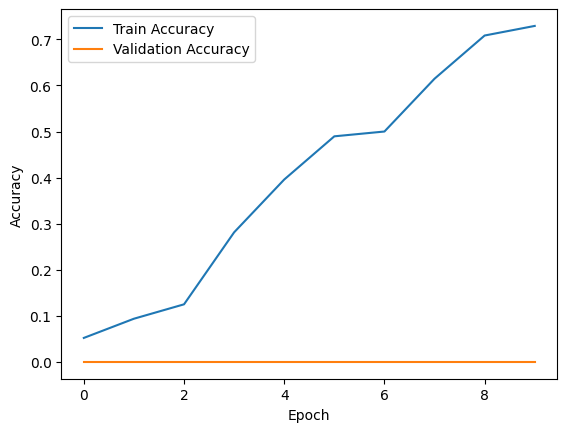

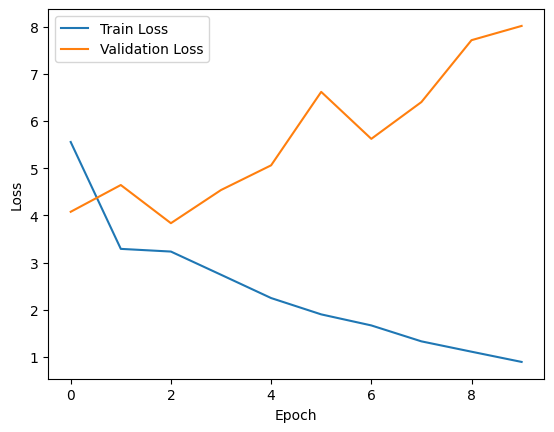

In [7]:
# แสดงกราฟความแม่นยำ
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# แสดงกราฟความสูญเสีย
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## 8. โหลดโมเดลที่บันทึกไว้

โหลดโมเดลและไฟล์ label ที่เป็นคู่กัน หากต้องการลองโมเดลเดิมโดยไม่ฝึกใหม่ ให้รันส่วนที่ 1 และ 2 แล้วเริ่มที่ส่วนนี้ ข้ามส่วนสร้างและฝึกโมเดล

In [8]:
from tensorflow.keras.models import load_model

# โหลด model
model = load_model(model_path)

# โหลด label map
reverse_label_map = np.load(label_path, allow_pickle=True).item()

### ตรวจข้อมูล label ที่บันทึกไว้

หมายเลขต้องตรงกับลำดับคลาสที่ใช้ฝึก ขณะนี้โค้ดสร้างการจับคู่จากลำดับใน CSV ซึ่งอาจต่างจากลำดับที่อ่านโฟลเดอร์

In [9]:
from pprint import pprint
pprint(reverse_label_map)

{0: 'Bangkok University',
 1: 'Burapha University',
 2: 'Chiang Mai University',
 3: 'Chulalongkorn University',
 4: 'Dhurakij Pundit University',
 5: 'Kasetsart University',
 6: 'Khon Kaen University',
 7: "King Mongkut's Institute of Technology Ladkrabang",
 8: "King Mongkut's University of Technology North Bangkok",
 9: "King Mongkut's University of Technology Thonburi",
 10: 'Mae Fah Luang University',
 11: 'Maejo University',
 12: 'Mahasarakham University',
 13: 'Mahidol University',
 14: 'Naresuan University',
 15: 'Panyapiwat Institute of Management',
 16: 'Rajamongala University of Technology Thanyaburi',
 17: 'Ramkhamhaeng University',
 18: 'Rangsit University',
 19: 'Saint Louis College',
 20: 'Silpakorn University',
 21: 'Srinakharinwirot University',
 22: 'Sripatum University',
 23: 'Suan Dusit University',
 24: 'Suan Sunandha Rajabhat University',
 25: 'Suranaree University of Technology',
 26: 'Thaksin University',
 27: 'Thammasat University',
 28: 'University of Phayao',

## 9. ทำนายภาพหนึ่งภาพ

แปลงเป็น RGB ปรับขนาด และปรับค่าพิกเซลให้เหมือนตอนฝึก จากนั้นเลือกคลาสที่ได้คะแนนสูงสุดแล้วค้นข้อมูลมหาวิทยาลัย ภาพที่ฟังก์ชันส่งกลับคือภาพที่ปรับขนาดสำหรับโมเดล ไม่ใช่ภาพต้นฉบับ

In [10]:
def predict_image(image_path):
    
    # เปิดและปรับขนาดภาพ
    img = Image.open(image_path)
    img = img.convert('RGB')
    img = img.resize((256, 256))
    img_array = np.array(img) / 255.0  # Normalize ข้อมูล
    img_array = np.expand_dims(img_array, axis=0)  # เพิ่มมิติ batch

    predictions = model.predict(img_array)
    predicted_label = np.argmax(predictions[0])
    
    # ใช้ label map เพื่อแปลง label เป็นชื่อ
    predicted_name_en = reverse_label_map.get(predicted_label, 'Unknown')
    predicted_name_th = university_info_th.get(predicted_name_en, 'Unknown')
    website_url = university_info.get(predicted_name_en, 'No URL available')
    
    return img, predicted_name_en, predicted_name_th, website_url

## 10. แสดงตัวอย่างการทำนาย

เปลี่ยน `test_image_path` เพื่อเลือกภาพอื่น ภาพตัวอย่างที่ให้มามีอยู่ในโฟลเดอร์ฝึกด้วย จึงใช้แสดงวิธีเรียกใช้งาน ไม่ใช่ประเมินความแม่นยำกับภาพใหม่

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
University (English) : Mae Fah Luang University
University (Thai) : มหาวิทยาลัยแม่ฟ้าหลวง
Website : https://www.mfu.ac.th


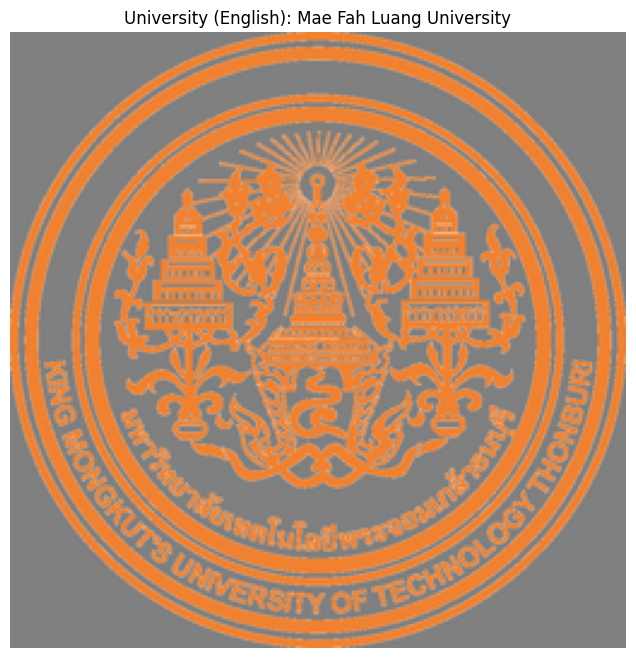

In [13]:
# ตัวอย่างการทดสอบ
test_image_path = PROJECT_ROOT / 'Image' / 'test5.png'
image, predicted_name_en, predicted_name_th, website_url = predict_image(test_image_path)

# แสดงผลลัพธ์
print(f"University (English) : {predicted_name_en}")
print(f"University (Thai) : {predicted_name_th}")
print(f"Website : {website_url}")

# แสดงภาพ
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title(f"University (English): {predicted_name_en}")
plt.axis('off')
plt.show()

## สิ่งที่ควรปรับปรุงต่อ

- บันทึกชื่อคลาสให้ตรงกับลำดับที่ใช้ฝึก และทำชื่อโฟลเดอร์ให้ตรงกับ CSV
- ประเมินด้วยภาพใหม่ที่ไม่อยู่ในข้อมูลฝึก
- เพิ่มภาพที่หลากหลายก่อนสรุปว่าโมเดลทำงานได้ดีในกรณีทั่วไป
- แยกภาพต้นฉบับออกจากภาพเข้าโมเดลเมื่อต้องการปรับการแสดงผล

Notebook นี้จำแนกภาพทั้งภาพ ไม่ได้หาตำแหน่งโลโก้ภายในภาพ และยังปฏิเสธภาพที่ไม่รู้จักได้ไม่แน่นอน